# AAL Sales Analysis Report - Q4 2020

AAL, established in 2000, is a well-known brand in Australia, particularly recognized for its clothing business. It has opened branches in various states, metropolises, and tier-1 and tier-2 cities across the country.
The brand caters to all age groups, from kids to the elderly.
Currently experiencing a surge in business, AAL is actively pursuing expansion opportunities. To facilitate informed investment decisions, the CEO has assigned the responsibility to the head of AAL’s sales and marketing (S&M) department. The specific tasks include:
-	Identify the states that are generating the highest revenues.
-	Develop sales programs for states with lower revenues. The head of sales and marketing has requested your assistance with this task.
Analyze the sales data of the company for the fourth quarter in Australia, examining it on a state-by-state basis. Provide insights to assist the company in making data-driven decisions for the upcoming year.


## 1. Data Wrangling

-	Ensure that the data is clean and free from any missing or incorrect entries.
    -	Inspect the data manually to identify missing or incorrect information using the functions isna() and notna().
-	Based on your knowledge of data analytics, include your recommendations for treating missing and incorrect data (dropping the null values or filling them).
-	Choose a suitable data wrangling technique—either data standardization or normalization. Execute the preferred normalization method and present the resulting data. (Normalization is the preferred approach for this problem.)
-	Share your insights regarding the application of the GroupBy() function for either data chunking or merging, and offer a recommendation based on your analysis


In [4]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", font_scale=1.0)
data = pd.read_csv('datasets/AusApparalSales4thQrt2020.csv')

print("Shape:", data.shape)
display(data.head())

Shape: (7560, 6)


,Date,Time,State,Group,Unit,Sales
0,1-Oct-2020,Morning,WA,Kids,8,20000
1,1-Oct-2020,Morning,WA,Men,8,20000
2,1-Oct-2020,Morning,WA,Women,4,10000
3,1-Oct-2020,Morning,WA,Seniors,15,37500
4,1-Oct-2020,Afternoon,WA,Kids,3,7500


In [5]:
# Manual inspection for missing, non-missing, duplicates, and incorrect formatting
print("Missing values per column:")
display(data.isna().sum().to_frame("missing_count"))

print("Non-missing values per column:")
display(data.notna().sum().to_frame("non_missing_count"))

print("Duplicate rows:", data.duplicated().sum())

# Clean text columns to remove leading/trailing spaces
clean_df = data.copy()
for col in ["State", "Group", "Time"]:
    clean_df[col] = clean_df[col].astype(str).str.strip()

# Convert the date column to datetime
clean_df["Date"] = pd.to_datetime(clean_df["Date"], format="%d-%b-%Y", errors="coerce")

print("Rows with invalid dates:", clean_df["Date"].isna().sum())
print("Unique States:", clean_df["State"].unique())
print("Unique Groups:", clean_df["Group"].unique())
print("Unique Time slots:", clean_df["Time"].unique())

display(clean_df.head())

Missing values per column:


,missing_count
Date,0
Time,0
State,0
Group,0
Unit,0
Sales,0


Non-missing values per column:


,non_missing_count
Date,7560
Time,7560
State,7560
Group,7560
Unit,7560
Sales,7560


Duplicate rows: 0
Rows with invalid dates: 0
Unique States: ['WA' 'NT' 'SA' 'VIC' 'QLD' 'NSW' 'TAS']
Unique Groups: ['Kids' 'Men' 'Women' 'Seniors']
Unique Time slots: ['Morning' 'Afternoon' 'Evening']


,Date,Time,State,Group,Unit,Sales
0,2020-10-01,Morning,WA,Kids,8,20000
1,2020-10-01,Morning,WA,Men,8,20000
2,2020-10-01,Morning,WA,Women,4,10000
3,2020-10-01,Morning,WA,Seniors,15,37500
4,2020-10-01,Afternoon,WA,Kids,3,7500


### Data quality recommendations

- The dataset has **no missing values** and **no duplicate rows**, so no dropping / filling is required.
- The `Date` column is converted to a proper datetime types so that weekly, monthly, and quarterly analysis becomes reliable.
- Min-Max normalization is applied to the numeric columns.

In [6]:
# Min-Max normalization for numeric columns
normalized_df = clean_df.copy()
numeric_cols = normalized_df.select_dtypes(include=np.number).columns

normalized_df[numeric_cols] = (
    normalized_df[numeric_cols] - normalized_df[numeric_cols].min()
) / (
    normalized_df[numeric_cols].max() - normalized_df[numeric_cols].min()
)

print("Normalized numeric columns (sample):")
display(normalized_df.head())

Normalized numeric columns (sample):


,Date,Time,State,Group,Unit,Sales
0,2020-10-01,Morning,WA,Kids,0.095238,0.095238
1,2020-10-01,Morning,WA,Men,0.095238,0.095238
2,2020-10-01,Morning,WA,Women,0.031746,0.031746
3,2020-10-01,Morning,WA,Seniors,0.206349,0.206349
4,2020-10-01,Afternoon,WA,Kids,0.015873,0.015873


### GroupBy insight

`groupby()` is the best fit for this dataset because it helps **chunk the data into meaningful business slices** such as state, group, time of day, week, month, and quarter.

For this project, `groupby()` is more valuable for **chunking and aggregation** than for merging. It makes it easy to:
- summarize sales by category,
- generate weekly/monthly/quarterly reports,
- compare performance across states and demographic groups,
- identify peak and off-peak periods.

## 2. Data Analysis

-	Perform descriptive statistical analysis on the data in the Sales and Unit columns. Utilize techniques such as mean, median, mode, and standard deviation for this analysis.
-	Identify the group with the highest sales and the group with the lowest sales based on the data provided.
-	Identify the group with the highest and lowest sales based on the data provided.
-	Generate weekly, monthly, and quarterly reports to document and present the results of the analysis conducted.
(Use suitable libraries such as NumPy, Pandas, and SciPy for performing the analysis.)

In [8]:
# Descriptive statistics for Sales and Unit
summary_rows = []
for col in ["Sales", "Unit"]:
    series = clean_df[col]
    try:
        from scipy import stats
        mode_value = stats.mode(series, keepdims=True).mode[0]
    except Exception:
        mode_value = series.mode().iat[0]
    summary_rows.append({
        "Metric": col,
        "Mean": series.mean(),
        "Median": series.median(),
        "Mode": mode_value,
        "Std Dev": series.std(),
        "Min": series.min(),
        "Max": series.max()
    })

summary_df = pd.DataFrame(summary_rows)
display(summary_df)

,Metric,Mean,Median,Mode,Std Dev,Min,Max
0,Sales,45013.558201,35000.0,22500,32253.506944,5000,162500
1,Unit,18.005423,14.0,9,12.901403,2,65


In [9]:
# Highest and lowest sales by demographic group and state
group_sales = clean_df.groupby("Group", as_index=False)["Sales"].sum().sort_values("Sales", ascending=False)
state_sales = clean_df.groupby("State", as_index=False)["Sales"].sum().sort_values("Sales", ascending=False)
time_sales = clean_df.groupby("Time", as_index=False)["Sales"].sum().sort_values("Sales", ascending=False)

print("Highest sales group:", group_sales.iloc[0]["Group"], "-", int(group_sales.iloc[0]["Sales"]))
print("Lowest sales group:", group_sales.iloc[-1]["Group"], "-", int(group_sales.iloc[-1]["Sales"]))
print("Highest sales state:", state_sales.iloc[0]["State"], "-", int(state_sales.iloc[0]["Sales"]))
print("Lowest sales state:", state_sales.iloc[-1]["State"], "-", int(state_sales.iloc[-1]["Sales"]))

print("\nSales by time of day:")
display(time_sales)

state_group_pivot = clean_df.pivot_table(index="State", columns="Group", values="Sales", aggfunc="sum").sort_index()
display(state_group_pivot)

Highest sales group: Men - 85750000
Lowest sales group: Seniors - 84037500
Highest sales state: VIC - 105565000
Lowest sales state: WA - 22152500

Sales by time of day:


,Time,Sales
2,Morning,114207500
0,Afternoon,114007500
1,Evening,112087500


Group,Kids,Men,Seniors,Women
State,,,,
NSW,18587500,19022500,18187500,19172500
NT,5700000,5762500,5465000,5652500
QLD,8510000,8392500,8190000,8325000
SA,14515000,14655000,14717500,14970000
TAS,5775000,5757500,5650000,5577500
VIC,26360000,26407500,26315000,26482500
WA,5625000,5752500,5512500,5262500


In [10]:
# Weekly, monthly, and quarterly reports
weekly_report = (
    clean_df.groupby(clean_df["Date"].dt.to_period("W-SUN"))
    .agg(Sales=("Sales", "sum"), Unit=("Unit", "sum"))
    .reset_index()
)
weekly_report["Date"] = weekly_report["Date"].astype(str)

monthly_report = (
    clean_df.groupby(clean_df["Date"].dt.to_period("M"))
    .agg(Sales=("Sales", "sum"), Unit=("Unit", "sum"))
    .reset_index()
)
monthly_report["Date"] = monthly_report["Date"].astype(str)

quarterly_report = (
    clean_df.groupby(clean_df["Date"].dt.to_period("Q"))
    .agg(Sales=("Sales", "sum"), Unit=("Unit", "sum"))
    .reset_index()
)
quarterly_report["Date"] = quarterly_report["Date"].astype(str)

print("Weekly report:")
display(weekly_report)

print("Monthly report:")
display(monthly_report)

print("Quarterly report:")
display(quarterly_report)

Weekly report:


,Date,Sales,Unit
0,2020-09-28/2020-10-04,15045000,6018
1,2020-10-05/2020-10-11,27002500,10801
2,2020-10-12/2020-10-18,26640000,10656
3,2020-10-19/2020-10-25,26815000,10726
4,2020-10-26/2020-11-01,21807500,8723
5,2020-11-02/2020-11-08,20865000,8346
6,2020-11-09/2020-11-15,21172500,8469
7,2020-11-16/2020-11-22,21112500,8445
8,2020-11-23/2020-11-29,21477500,8591
9,2020-11-30/2020-12-06,29622500,11849


Monthly report:


,Date,Sales,Unit
0,2020-10,114290000,45716
1,2020-11,90682500,36273
2,2020-12,135330000,54132


Quarterly report:


,Date,Sales,Unit
0,2020Q4,340302500,136121


## 3. Data Visualization

- Use suitable data visualization libraries to construct a dashboard for the head of sales and marketing. The dashboard should encompass key parameters:
    o	State-wise sales analysis for different demographic groups (kids, women, men, and seniors).
    o	Group-wise sales analysis (Kids, Women, Men, and Seniors) across various states.
    o	Time-of-the-day analysis: Identify peak and off-peak sales periods to facilitate strategic planning for S&M teams. This information aids in designing programs like hyper-personalization and Next Best Offers to enhance sales.
- Ensure the visualization is clear and accessible for effective decision-making by the head of sales and marketing (S&M).The dashboard must contain daily, weekly, monthly, and quarterly charts. (Any visualization library can be used for this purpose. However, since statistical analysis is being done, Seaborn is preferred.)
-Include your recommendation and indicate why you are choosing the recommended visualization package.


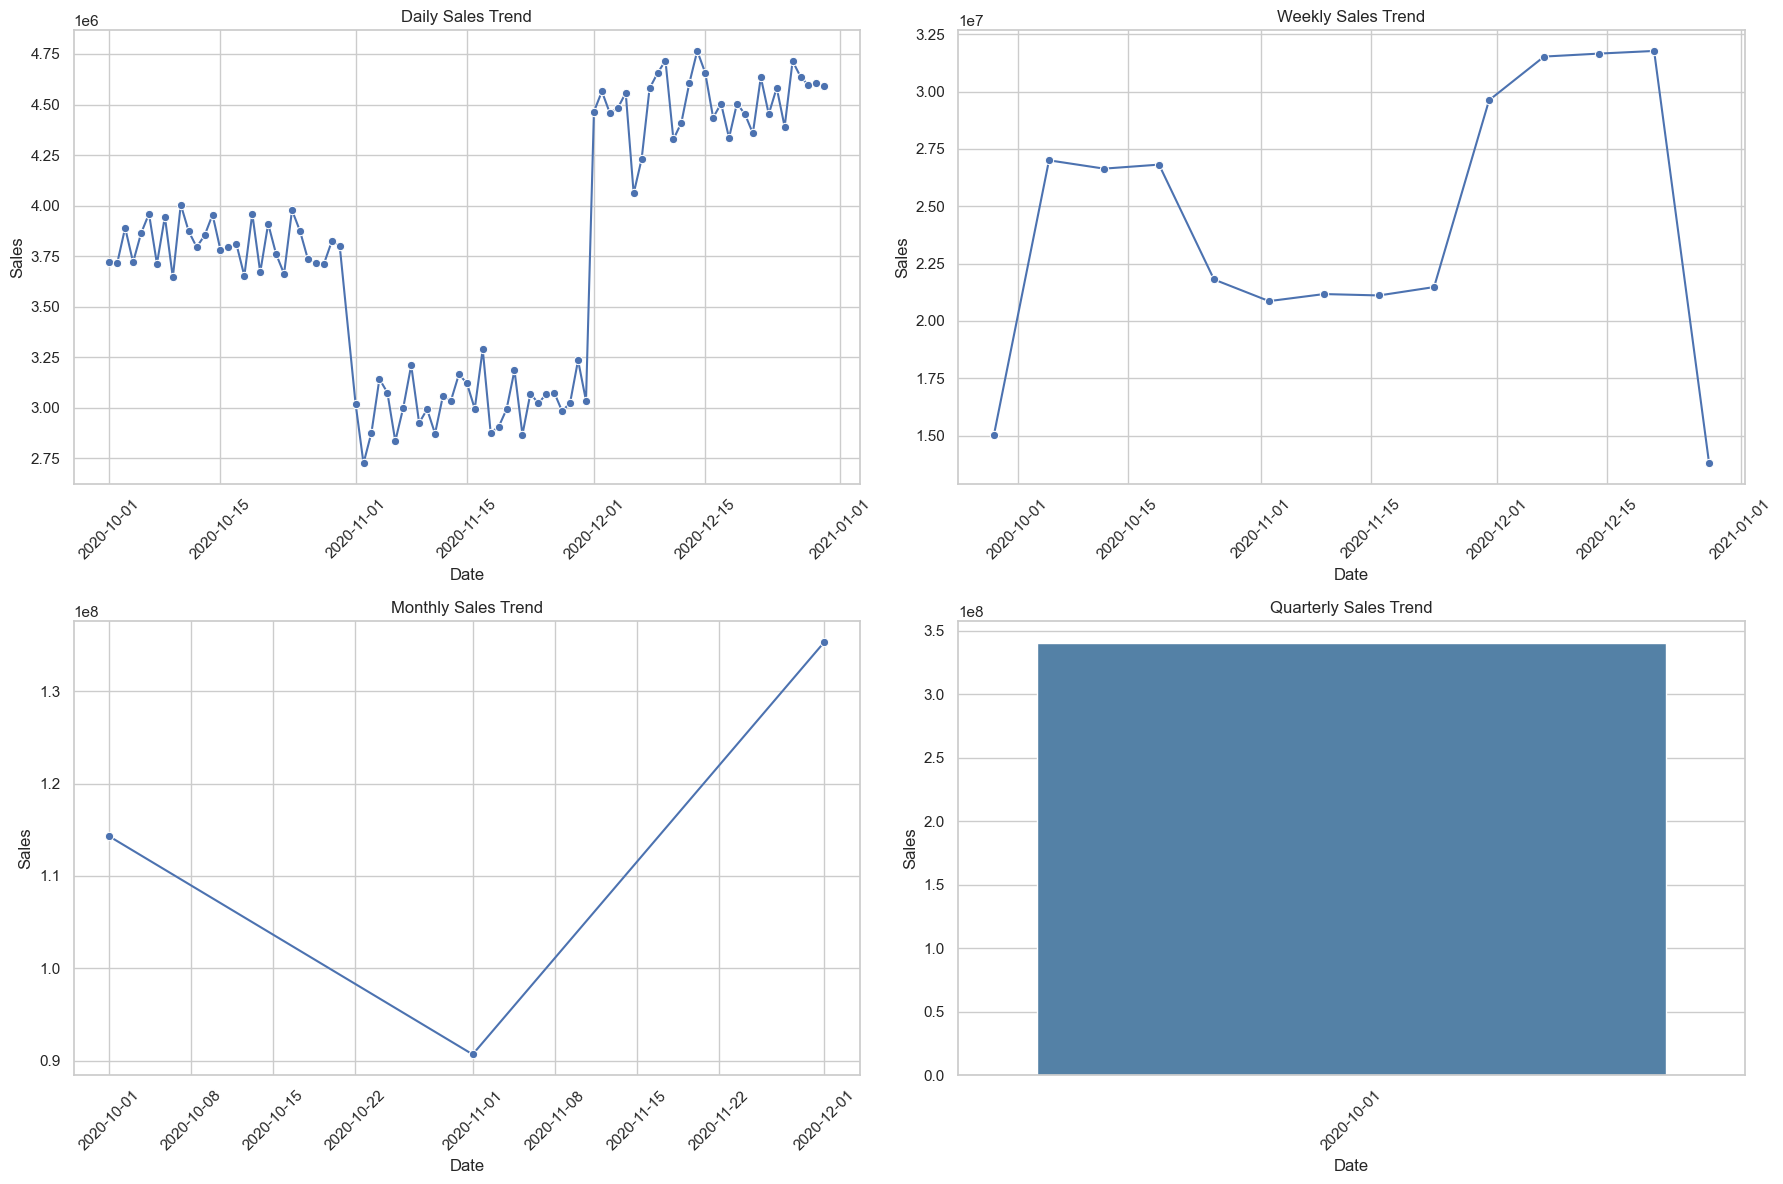

In [11]:
# Dashboard: daily, weekly, monthly, and quarterly sales charts
daily_report = clean_df.groupby("Date", as_index=False).agg(Sales=("Sales", "sum"), Unit=("Unit", "sum"))
weekly_chart = clean_df.groupby(clean_df["Date"].dt.to_period("W-SUN")).agg(Sales=("Sales", "sum")).reset_index()
weekly_chart["Date"] = weekly_chart["Date"].dt.start_time
monthly_chart = clean_df.groupby(clean_df["Date"].dt.to_period("M")).agg(Sales=("Sales", "sum")).reset_index()
monthly_chart["Date"] = monthly_chart["Date"].dt.start_time
quarterly_chart = clean_df.groupby(clean_df["Date"].dt.to_period("Q")).agg(Sales=("Sales", "sum")).reset_index()
quarterly_chart["Date"] = quarterly_chart["Date"].dt.start_time

fig, axes = plt.subplots(2, 2, figsize=(18, 12))

sns.lineplot(data=daily_report, x="Date", y="Sales", ax=axes[0, 0], marker="o")
axes[0, 0].set_title("Daily Sales Trend")
axes[0, 0].tick_params(axis="x", rotation=45)

sns.lineplot(data=weekly_chart, x="Date", y="Sales", ax=axes[0, 1], marker="o")
axes[0, 1].set_title("Weekly Sales Trend")
axes[0, 1].tick_params(axis="x", rotation=45)

sns.lineplot(data=monthly_chart, x="Date", y="Sales", ax=axes[1, 0], marker="o")
axes[1, 0].set_title("Monthly Sales Trend")
axes[1, 0].tick_params(axis="x", rotation=45)

sns.barplot(data=quarterly_chart, x="Date", y="Sales", ax=axes[1, 1], color="steelblue")
axes[1, 1].set_title("Quarterly Sales Trend")
axes[1, 1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

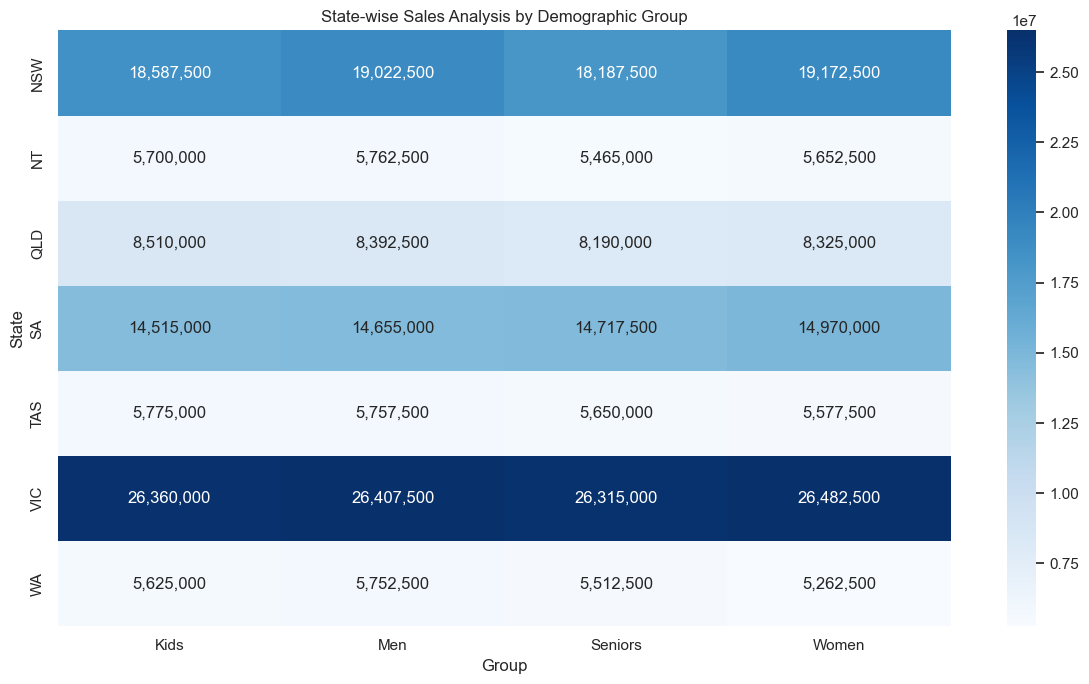

In [12]:
# State-wise sales analysis for different demographic groups
plt.figure(figsize=(12, 7))
sns.heatmap(state_group_pivot, annot=True, fmt=",.0f", cmap="Blues")
plt.title("State-wise Sales Analysis by Demographic Group")
plt.xlabel("Group")
plt.ylabel("State")
plt.tight_layout()
plt.show()

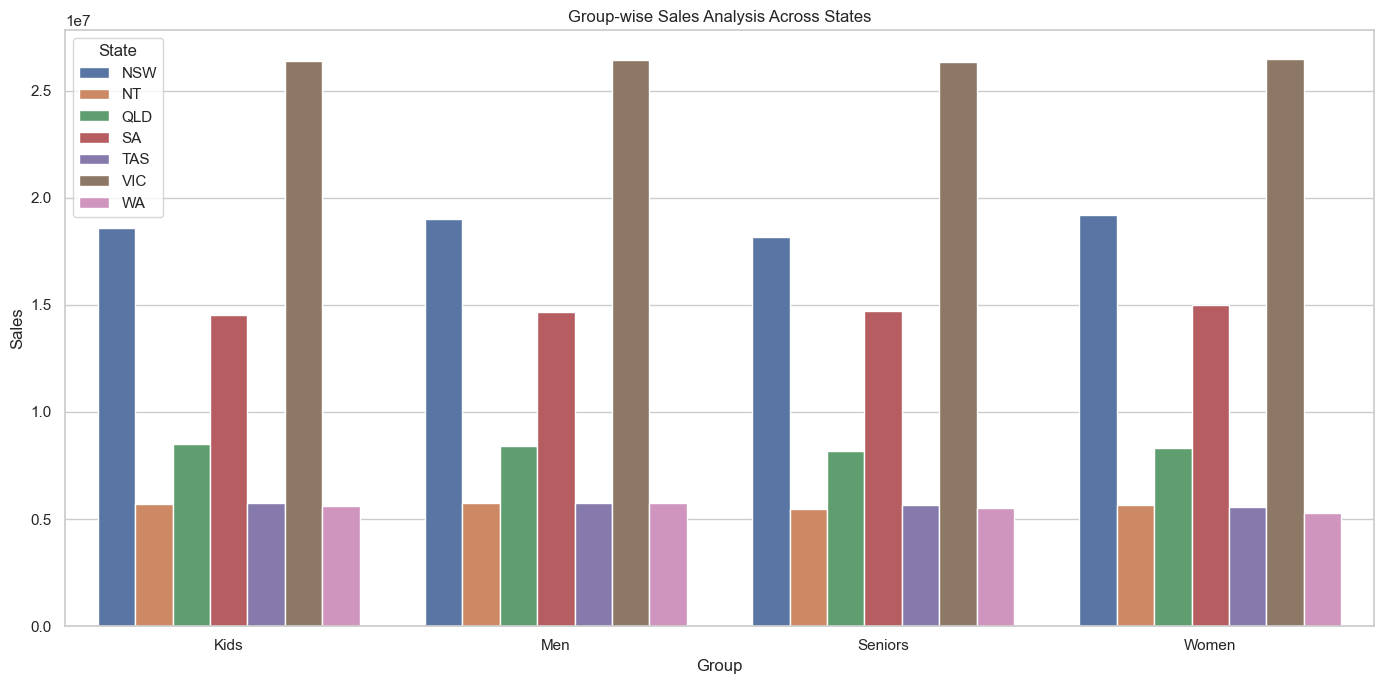

In [13]:
# Group-wise sales analysis across states
plt.figure(figsize=(14, 7))
sns.barplot(
    data=clean_df.groupby(["Group", "State"], as_index=False)["Sales"].sum(),
    x="Group",
    y="Sales",
    hue="State"
)
plt.title("Group-wise Sales Analysis Across States")
plt.tight_layout()
plt.show()

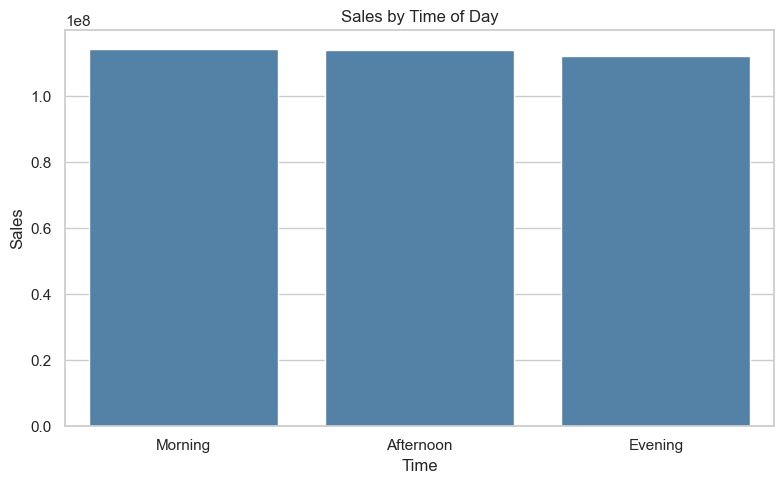

Peak sales period: Morning
Off-peak sales period: Evening


In [14]:
# Time-of-day analysis
time_order = ["Morning", "Afternoon", "Evening"]
time_sales_ordered = (
    clean_df.groupby("Time", as_index=False)["Sales"].sum()
    .set_index("Time")
    .reindex(time_order)
    .reset_index()
)

plt.figure(figsize=(8, 5))
sns.barplot(data=time_sales_ordered, x="Time", y="Sales", color="steelblue")
plt.title("Sales by Time of Day")
plt.tight_layout()
plt.show()

peak_time = time_sales_ordered.loc[time_sales_ordered["Sales"].idxmax(), "Time"]
off_peak_time = time_sales_ordered.loc[time_sales_ordered["Sales"].idxmin(), "Time"]

print("Peak sales period:", peak_time)
print("Off-peak sales period:", off_peak_time)

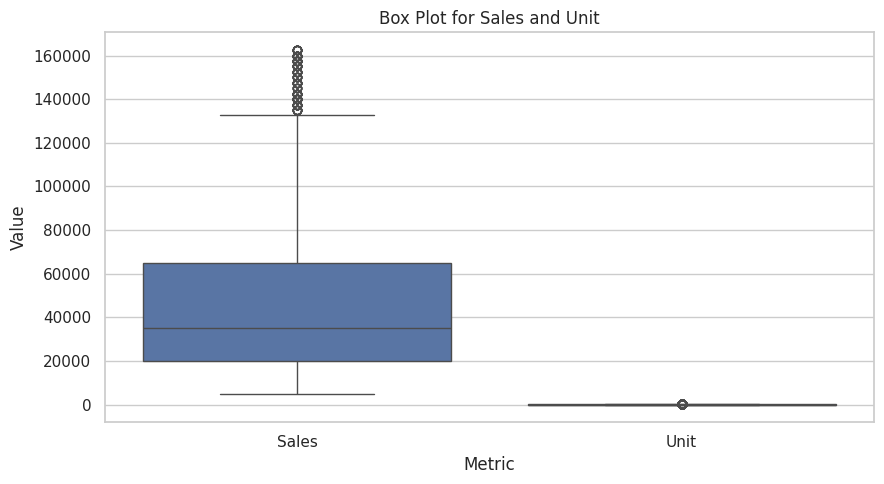

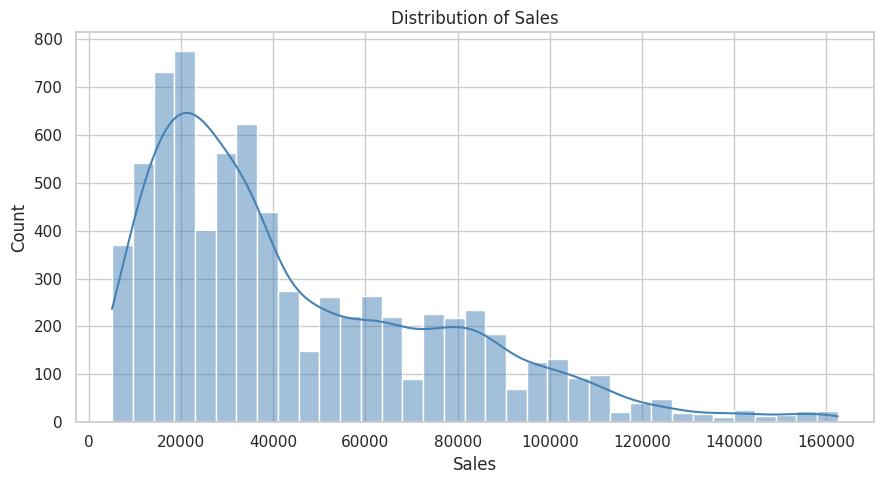

In [11]:
# Box plot for descriptive statistics
melted_stats = clean_df[["Sales", "Unit"]].melt(var_name="Metric", value_name="Value")

plt.figure(figsize=(9, 5))
sns.boxplot(data=melted_stats, x="Metric", y="Value")
plt.title("Box Plot for Sales and Unit")
plt.tight_layout()
plt.show()

# Distribution plot
plt.figure(figsize=(9, 5))
sns.histplot(clean_df["Sales"], kde=True, color="steelblue")
plt.title("Distribution of Sales")
plt.tight_layout()
plt.show()

## 4. Key Findings and Recommendations

- **VIC** is the highest-revenue state, while **WA** is the lowest-revenue state.
- The **Men** group contributes the highest sales, while **Seniors** contribute the lowest.
- **Morning** is the peak sales period and **Evening** is the off-peak period.
- December performs best among the months in Q4 2020.

### Recommended actions
- Run targeted promotions and localized campaigns in low-revenue states such as **WA, NT, TAS, and QLD**.
- Build specific offers for the **Seniors** group to improve conversion.